# Syntetická validace: známé plazma, simulované signály sond

**SIMULOVANÁ DATA, NE DATA Z COMPASSU.** Tento notebook nečte žádný soubor ÚFP; nepotřebuje vůbec žádná data.
Plazma, obrys komory a 16 + 8 sond jsou vymyšlené (velikostí jen odpovídají COMPASSu) a každý obrázek a tabulka níže se týká
té simulace.

Co testuje: dokáže recept sítě s maskou z hlavní práce zrekonstruovat **známé** plazma (magnetickou osu, elongaci,
triangularitu, dolní X bod) z 24 signálů sond, při dělení po celých syntetických výbojích, s šumem o velikosti
zašuměného souboru organizátorů i bez něj? Je to uzavřený test požadovaný v `docs/internal/review-physics.md` (H1, oddíl 2).

Co **neříká**: nic o štítcích z COMPASSu, o skutečné kalibraci, proudech v komoře ani disrupcích.
Úplný seznam a čísla běhu s 3 semínky jsou v `results/synthetic-validation.md`; tento notebook pouští týž
postup s 1 semínkem, takže jeho čísla odpovídají té zprávě jen až na šum semínka. Proběhne od začátku do konce za pár minut na 2 vláknech.

In [1]:
import sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

torch.set_num_threads(2)
here = Path.cwd()
sys.path.insert(0, str(next(p / "analysis" for p in [here, here.parent] if (p / "analysis" / "synth_equilibrium.py").exists())))
import synth_equilibrium as se
import synth_validation as sv
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})
T0 = time.time()
BANNER = "SIMULOVANÁ DATA, NE DATA Z COMPASSU"


## 1. Řeší generátor rovnici, kterou slibuje?

Každé Solovjovovo řešení je součet přesných homogenních řešení a jednoho partikulárního; kontroly níže se tady měří znovu.
`ampere_ratio` je křivkový integrál poloidálního pole podél hranice plazmatu dělený mu0 krát proud plazmatu (mělo by být 1).

In [2]:
checks = sv.generator_checks()
print(f"homogenní řešení, největší |Delta* phi| : {checks['homogeneous_residual']:.1e}")
for cfg in ("limited", "diverted"):
    print(cfg, {k: (round(v, 4) if k != "source_residual" else f"{v:.1e}") for k, v in checks[cfg].items()})

homogenní řešení, největší |Delta* phi| : 3.4e-13
limited {'source_residual': '4.4e-16', 'ampere_ratio': 1.0, 'kappa_requested': 1.5, 'kappa_measured': 1.5, 'delta_requested': 0.3, 'delta_measured': 0.3}
diverted {'source_residual': '2.4e-14', 'ampere_ratio': 1.0001, 'kappa_requested': 1.5, 'kappa_measured': 1.575, 'delta_requested': 0.3, 'delta_measured': 0.315}


## 2. Čtyři příklady rovnováhy na vymyšlené komoře

Červená čára: hranice plazmatu `psi = 0`; šedě: magnetické plochy; zelené trojúhelníky: 16 tangenciálních sond pole; fialové čtverce: 8 smyček toku;
červený plus: magnetická osa; červený křížek: X bod. Komora je vymyšlená zaoblená krabice, ne komora COMPASSu.

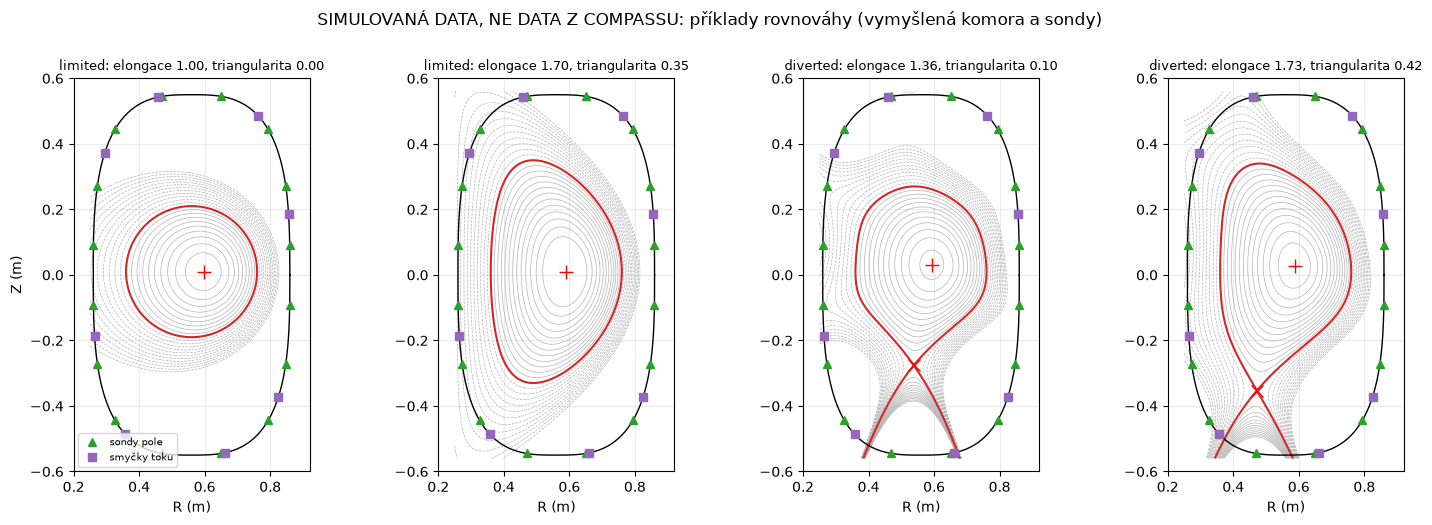

In [3]:
cases = [("limited", 1.0, 0.0), ("limited", 1.7, 0.35), ("diverted", 1.3, 0.1), ("diverted", 1.65, 0.4)]
s = np.linspace(0, 2 * np.pi, 400)
vR, vZ, _, _ = se.vessel_point(s)
L = se.PROBE_LAYOUT
fig, axs = plt.subplots(1, 4, figsize=(15, 5.2))
R, Z = np.meshgrid(np.linspace(0.25, 0.87, 160), np.linspace(-0.56, 0.56, 240))
for ax, (cfg, k, dl) in zip(axs, cases):
    eq = se.Equilibrium(0.56, 0.2, k, dl, 0.1, 200e3, 0.01, cfg)
    P = eq.psi(R, Z)
    lim = abs(eq.psi0) * 0.04
    ax.contour(R, Z, P, levels=np.linspace(-lim, lim, 25), colors="0.7", linewidths=0.5)
    ax.contour(R, Z, P, levels=[0], colors="tab:red", linewidths=1.5)
    ax.plot(vR, vZ, "k", lw=1)
    ax.plot(L["coil_R"], L["coil_Z"], "^", color="tab:green", label="sondy pole")
    ax.plot(L["loop_R"], L["loop_Z"], "s", color="tab:purple", label="smyčky toku")
    t = eq.truth()
    ax.plot(t["R_mag_axis"], t["Z_mag_axis"], "r+", ms=10)
    if cfg == "diverted":
        ax.plot(t["R_x_point"], t["Z_x_point"], "rx", ms=8)
    ax.set_xlim(0.2, 0.92); ax.set_ylim(-0.6, 0.6); ax.set_aspect("equal")
    ax.set_title(f"{cfg}: elongace {t['elongation']:.2f}, triangularita {t['triangularity']:.2f}", fontsize=9)
    ax.set_xlabel("R (m)")
axs[0].set_ylabel("Z (m)"); axs[0].legend(loc="lower left", fontsize=7)
fig.suptitle(BANNER + ": příklady rovnováhy (vymyšlená komora a sondy)", y=1.0)
plt.tight_layout(); plt.show()

## 3. Vygenerování syntetických výbojů

40 výbojů po 100 časových řezech; každý výboj je jeden základní tvar, který se v čase hladce mění. Sloupce pravdy se měří na
hotovém řešení (osa, X bod, krajní body hranice), nekopírují se z požadovaných parametrů.

In [4]:
t0 = time.time()
data = se.generate(40, 100, seed=0)
X, Y, G = data["X"], data["Y"], data["groups"]
print(f"{len(X)} řádků, {len(np.unique(G))} výbojů, {time.time() - t0:.0f} s; znovu vylosovaných výbojů: {data['n_redrawn']}; "
      f"podíl limiterových řádků {np.nanmean(Y[:, -1]):.3f}")
stats = sv.data_stats(data)
pd.DataFrame(stats).T[["unit", "min", "max", "std"]].round(4)

4000 řádků, 40 výbojů, 42 s; znovu vylosovaných výbojů: 0; podíl limiterových řádků 0.425


,unit,min,max,std
plasma_current,kA,44.036366,252.958908,51.971925
R_mag_axis,mm,561.409591,614.638712,10.686442
Z_mag_axis,mm,-32.062724,47.152921,18.226661
elongation,,1.0,1.719749,0.156545
triangularity,,-0.0525,0.397471,0.12134
R_x_point,mm,467.426867,584.135475,27.752701
Z_x_point,mm,-381.185852,-250.284739,27.060979
is_limited,,0.0,1.0,0.494343


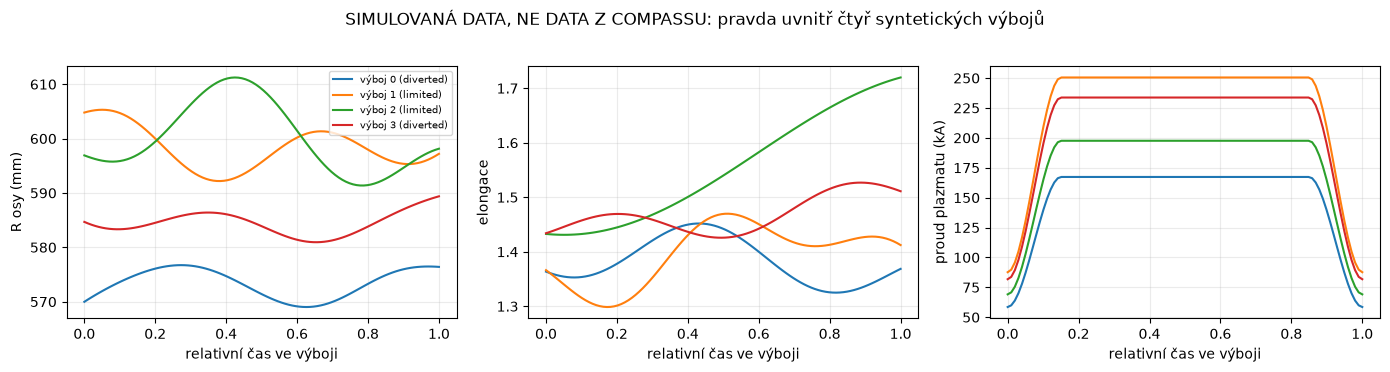

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
for d in (0, 1, 2, 3):
    r = G == d
    cfg = "limited" if Y[r, -1][0] else "diverted"
    axs[0].plot(data["time"][r], Y[r, 1] * 1e3, label=f"výboj {d} ({cfg})")
    axs[1].plot(data["time"][r], Y[r, 3])
    axs[2].plot(data["time"][r], Y[r, 0] * 1e-3)
axs[0].set_ylabel("R osy (mm)"); axs[1].set_ylabel("elongace"); axs[2].set_ylabel("proud plazmatu (kA)")
for a in axs: a.set_xlabel("relativní čas ve výboji")
axs[0].legend(fontsize=7)
fig.suptitle(BANNER + ": pravda uvnitř čtyř syntetických výbojů", y=1.02); plt.tight_layout(); plt.show()

## 4. Šum, který se přidává

Bílý šum na kanál, 15 % (cívky) a 9 % (smyčky toku) rozptylu kanálu přes celou sadu, tedy velikosti změřené pro
zašuměný soubor organizátorů v `results/data-checks.md`. Síť se testuje na šumu, který při učení neviděla.

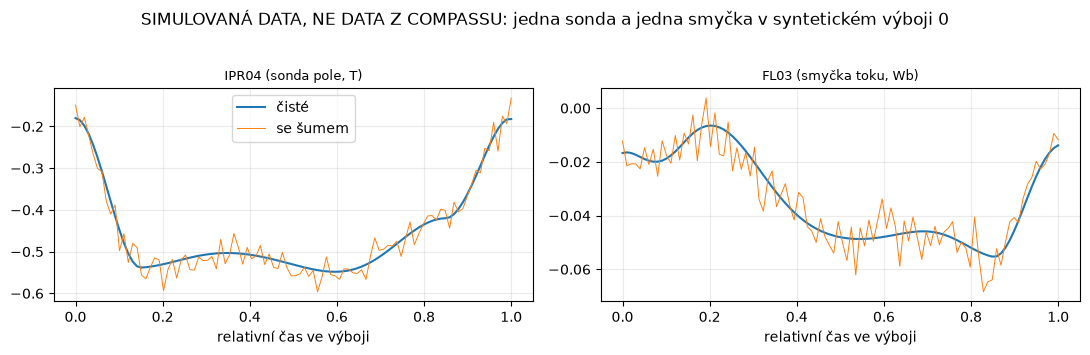

sm. odchylka šumu / sm. odchylka signálu, cívky: [0.151 0.149 0.15  0.15 ] ... smyčky toku: [0.093 0.091 0.089 0.09 ] ...


In [6]:
Xn = sv.add_noise(X, np.random.default_rng(1001), X.std(0))
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
r = G == 0
for ax, j, name in ((axs[0], 3, se.SIGNAL_NAMES[3] + " (sonda pole, T)"), (axs[1], 18, se.SIGNAL_NAMES[18] + " (smyčka toku, Wb)")):
    ax.plot(data["time"][r], X[r, j], label="čisté"); ax.plot(data["time"][r], Xn[r, j], lw=0.7, label="se šumem")
    ax.set_title(name, fontsize=9); ax.set_xlabel("relativní čas ve výboji")
axs[0].legend()
fig.suptitle(BANNER + ": jedna sonda a jedna smyčka v syntetickém výboji 0", y=1.03); plt.tight_layout(); plt.show()
print("sm. odchylka šumu / sm. odchylka signálu, cívky:", np.round((Xn - X)[:, :16].std(0) / X[:, :16].std(0), 3)[:4], "... smyčky toku:",
      np.round((Xn - X)[:, 16:].std(0) / X[:, 16:].std(0), 3)[:4], "...")

## 5. Učení a hodnocení proti ZNÁMÉ pravdě

Recept z `analysis/common.py` (256-256-128, SiLU, AdamW, standardizované vstupy i cíle, ztráta maskovaná na cíle, které existují),
5násobný GroupKFold po syntetických výbojích, tady jedno semínko (ve zprávě 3). Dvě nastavení epoch: 60 je výchozí hodnota receptu, ale je to jen asi
400 kroků optimalizace na 3 200 řádcích, 400 je dost dlouho na to, aby se síť naučila. Tři scénáře: učeno čistě / testováno čistě, učeno čistě / testováno zašuměně,
učeno zašuměně / testováno zašuměně. Chyby se sčítají mimo učicí sadu; polohy jsou v mm; nRMSE je RMSE dělené směrodatnou odchylkou pravdy
(1,0 = vždy tipovat průměr).

In [7]:
raw = {}
for e in (60, 400):
    t0 = time.time()
    raw[e] = sv.cross_validate(data, epochs=e, seeds=1)
    print(f"epoch {e}: {time.time() - t0:.0f} s")
runs = {e: sv.summarise(r) for e, r in raw.items()}

train clean, test clean: done, 8 s; MLP R axis MAE 1.875 mm


train clean, test noisy: done, 12 s; MLP R axis MAE 4.637 mm


train noisy, test noisy: done, 17 s; MLP R axis MAE 4.958 mm
epoch 60: 17 s


train clean, test clean: done, 31 s; MLP R axis MAE 0.775 mm


train clean, test noisy: done, 62 s; MLP R axis MAE 5.140 mm


train noisy, test noisy: done, 93 s; MLP R axis MAE 6.576 mm
epoch 400: 93 s


In [8]:
def table(e, model="mlp"):
    rows = []
    for t in sv.TARGETS:
        row = {"target": t, "unit": sv.UNIT[t][1], "truth std": runs[e]["train clean, test clean"]["mlp"][t]["truth_std"]}
        for a, b in sv.SCENARIOS:
            m = runs[e][f"train {a}, test {b}"][model][t]
            row[f"MAE {a}>{b}"] = m["mae"]; row[f"nRMSE {a}>{b}"] = m["nrmse"]
        rows.append(row)
    return pd.DataFrame(rows).set_index("target").round(4)
print("MLP, 400 epoch, simulovaná data, ne data z COMPASSu"); table(400)

MLP, 400 epoch, simulovaná data, ne data z COMPASSu


,unit,truth std,MAE clean>clean,nRMSE clean>clean,MAE clean>noisy,nRMSE clean>noisy,MAE noisy>noisy,nRMSE noisy>noisy
target,,,,,,,,
plasma_current,kA,51.9719,2.2726,0.0701,9.1638,0.2335,16.5454,0.4180
R_mag_axis,mm,10.6864,0.7753,0.1080,5.1397,0.6697,6.5760,0.7749
Z_mag_axis,mm,18.2267,0.6402,0.0547,4.2975,0.3437,5.0700,0.3682
elongation,,0.1565,0.0062,0.0588,0.0297,0.2593,0.0427,0.3824
triangularity,,0.1213,0.0043,0.0557,0.0181,0.2033,0.0284,0.3115
R_x_point,mm,27.7527,0.5804,0.0326,2.4217,0.1221,3.4794,0.1771
Z_x_point,mm,27.0610,1.1495,0.0600,5.0019,0.2562,7.9374,0.3853
is_limited,,0.4943,0.0132,0.0404,0.0442,0.1421,0.0336,0.1171


In [9]:
print("MLP, 60 epoch (výchozí hodnota receptu), simulovaná data, ne data z COMPASSu"); table(60)

MLP, 60 epoch (výchozí hodnota receptu), simulovaná data, ne data z COMPASSu


,unit,truth std,MAE clean>clean,nRMSE clean>clean,MAE clean>noisy,nRMSE clean>noisy,MAE noisy>noisy,nRMSE noisy>noisy
target,,,,,,,,
plasma_current,kA,51.9719,5.6226,0.1554,9.7764,0.2451,11.3511,0.2900
R_mag_axis,mm,10.6864,1.8754,0.2664,4.6366,0.5778,4.9577,0.6043
Z_mag_axis,mm,18.2267,1.4271,0.1196,3.9699,0.3147,3.5947,0.2725
elongation,,0.1565,0.0148,0.1278,0.0297,0.2520,0.0321,0.2703
triangularity,,0.1213,0.0064,0.0787,0.0178,0.1992,0.0183,0.2016
R_x_point,mm,27.7527,1.1141,0.0535,2.3571,0.1138,2.1133,0.1032
Z_x_point,mm,27.0610,2.2782,0.1152,4.9284,0.2475,4.7007,0.2250
is_limited,,0.4943,0.0291,0.0833,0.0495,0.1412,0.0389,0.1183


In [10]:
print("základ ridge, simulovaná data, ne data z COMPASSu"); table(400, "ridge")

základ ridge, simulovaná data, ne data z COMPASSu


,unit,truth std,MAE clean>clean,nRMSE clean>clean,MAE clean>noisy,nRMSE clean>noisy,MAE noisy>noisy,nRMSE noisy>noisy
target,,,,,,,,
plasma_current,kA,51.9719,2.2053,0.0590,13.4484,0.3241,9.7396,0.2350
R_mag_axis,mm,10.6864,2.1534,0.2847,6.3124,0.7483,4.9169,0.5843
Z_mag_axis,mm,18.2267,6.1326,0.4485,8.0148,0.5693,6.3617,0.4597
elongation,,0.1565,0.0427,0.3784,0.0607,0.4979,0.0499,0.4186
triangularity,,0.1213,0.0360,0.4041,0.0425,0.4568,0.0360,0.3914
R_x_point,mm,27.7527,7.0479,0.3681,9.3463,0.4441,7.1314,0.3545
Z_x_point,mm,27.0610,7.9470,0.3991,12.3432,0.5859,8.2827,0.3960
is_limited,,0.4943,0.2050,0.5093,0.2465,0.6224,0.2079,0.5027


## 6. Odhad proti známé pravdě (čisté signály, mimo učicí sadu, 400 epoch)

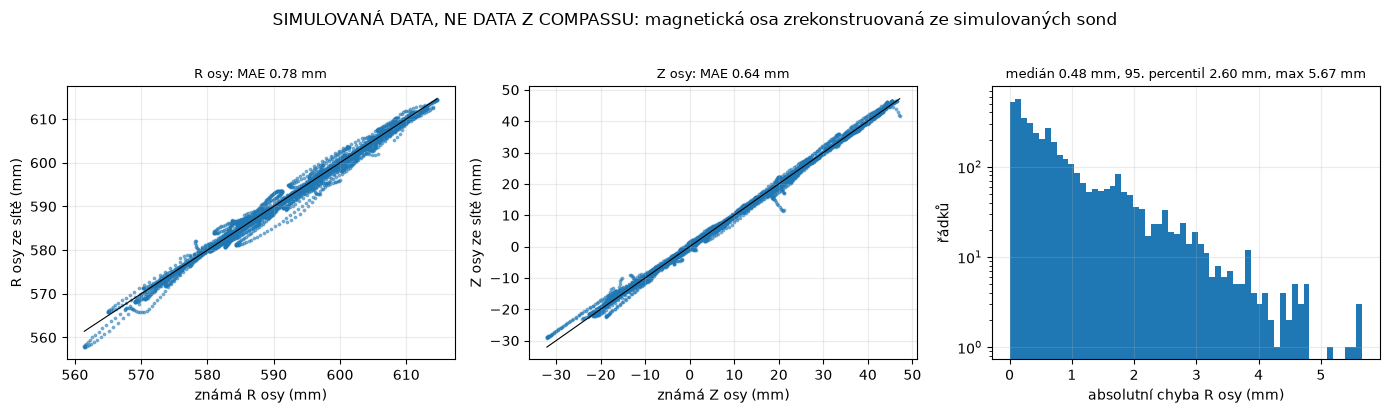

In [11]:
ex = raw[400]["train clean, test clean"]["oof_example"]
truth, pred = np.array(ex["truth"]) * 1e3, np.array(ex["pred"]) * 1e3
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
for ax, j, name in ((axs[0], 0, "R osy"), (axs[1], 1, "Z osy")):
    ax.scatter(truth[:, j], pred[:, j], s=3, alpha=0.5)
    lo, hi = truth[:, j].min(), truth[:, j].max()
    ax.plot([lo, hi], [lo, hi], "k", lw=0.8); ax.set_xlabel(f"známá {name} (mm)"); ax.set_ylabel(f"{name} ze sítě (mm)")
    ax.set_title(f"{name}: MAE {np.abs(pred[:, j] - truth[:, j]).mean():.2f} mm", fontsize=9)
err = np.abs(pred[:, 0] - truth[:, 0])
axs[2].hist(err, bins=60, log=True); axs[2].set_xlabel("absolutní chyba R osy (mm)"); axs[2].set_ylabel("řádků")
axs[2].set_title(f"medián {np.median(err):.2f} mm, 95. percentil {np.percentile(err, 95):.2f} mm, max {err.max():.2f} mm", fontsize=9)
fig.suptitle(BANNER + ": magnetická osa zrekonstruovaná ze simulovaných sond", y=1.02); plt.tight_layout(); plt.show()

## 7. Čtení

- Test ukazuje, že **metoda dokáže ze simulovaných signálů sond zrekonstruovat známé plazma**, na celých syntetických výbojích, které nikdy neviděla.
  Se šumem velikosti ze zašuměného souboru organizátorů chyby poloh vzrostou z pod milimetru nebo zhruba milimetru na několik milimetrů;
  přesná čísla tohoto běhu jsou v tabulkách výše.
- **Neříká nic o skutečných štítcích z COMPASSu.** Simulovaná rodina má asi sedm volných parametrů, přesné vymyšlené sondy, žádné proudy v komoře ani cívkách,
  žádnou chybu kalibrace a žádné disrupce (viz `results/synthetic-validation.md`, „What is NOT simulated“), takže tyto chyby nejsou ani mezí
  pro shodu s rekonstrukcí ústavu v `results/final-evaluation.md`, ani se s ní nedají srovnávat.
- Čistá chyba není nulová, ačkoli je rodina deterministická a bez šumu: je to aproximační chyba této sítě při této velikosti dat.

In [12]:
print(f"notebook celkem: {time.time() - T0:.0f} s na {torch.get_num_threads()} vláknech")

notebook celkem: 154 s na 2 vláknech
